In [38]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [44]:
df = pd.read_csv(r"C:\Users\Administrator\Documents\portofolio github\Diwali sales analyst\Diwali sales data.csv",encoding = 'unicode_escape')
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0,NaN,NaN
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0,NaN,NaN
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0,NaN,NaN
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0,NaN,NaN


In [45]:
df.drop(['Status','unnamed1'],axis =1, inplace =  True)

In [46]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0


In [47]:
df.dtypes

User_ID               int64
Cust_name            object
Product_ID           object
Gender               object
Age Group            object
Age                   int64
Marital_Status        int64
State                object
Zone                 object
Occupation           object
Product_Category     object
Orders                int64
Amount              float64
dtype: object

In [48]:
df.isnull().sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age Group            0
Age                  0
Marital_Status       0
State                0
Zone                 0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

In [49]:
average_amount = df['Amount'].mean()
average_amount

np.float64(9453.610857727557)

In [51]:
df['Amount'] = df['Amount'].fillna(average_amount)

In [52]:
df.isnull().sum()

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

In [53]:
df['Amount'].dtypes

dtype('float64')

In [54]:
df['Amount'] = df['Amount'].astype(int)

In [55]:
df['Amount'].dtypes

dtype('int64')

In [56]:
df.nunique()

User_ID             3755
Cust_name           1250
Product_ID          2351
Gender                 2
Age Group              7
Age                   81
Marital_Status         2
State                 16
Zone                   5
Occupation            15
Product_Category      18
Orders                 4
Amount              6584
dtype: int64

In [57]:
df.shape

(11251, 13)

In [58]:
df[['Age','Orders','Amount']].describe()

,Age,Orders,Amount
count,11251.000000,11251.000000,11251.000000
mean,35.421207,2.489290,9453.609901
std,12.754122,1.115047,5219.569169
min,12.000000,1.000000,188.000000
25%,27.000000,1.500000,5443.500000
50%,33.000000,2.000000,8110.000000
75%,43.000000,3.000000,12671.000000
max,92.000000,4.000000,23952.000000


In [59]:
df.describe(include=['object'])

,Cust_name,Product_ID,Gender,Age Group,State,Zone,Occupation,Product_Category
count,11251,11251,11251,11251,11251,11251,11251,11251
unique,1250,2351,2,7,16,5,15,18
top,Vishakha,P00265242,F,26-35,Uttar Pradesh,Central,IT Sector,Clothing & Apparel
freq,42,53,7842,4543,1946,4296,1588,2655


ANALISIS DATA EKSPLORASI

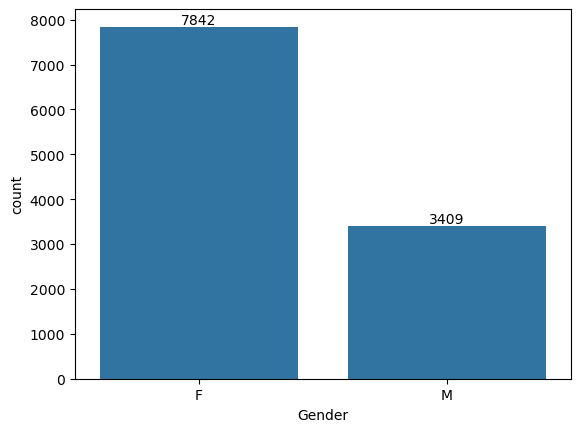

In [61]:
#diagram batang untuk gender
ax = sns.countplot(x='Gender',data = df)

for bars in ax.containers:
    ax.bar_label(bars)

In [65]:
df.groupby(['Gender'],as_index = False)['Amount'].sum()

,Gender,Amount
0,F,74430383
1,M,31932182


<Axes: xlabel='Gender', ylabel='Amount'>

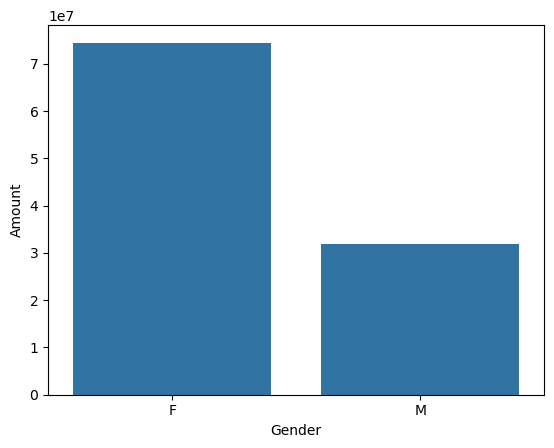

In [68]:
#diagram batang untuk gender VS jumlah total sales gender 
sales_gender = df.groupby(['Gender'],as_index = False)['Amount'].sum().sort_values(by='Amount',ascending = False)
sns.barplot(x = 'Gender', y='Amount', data = sales_gender)

Analisis di atas jelas menunjukkan bahwa pembeli perempuan relatif lebih tinggi dibandingkan pembeli laki-laki. Selain itu, jumlah yang dibelanjakan oleh perempuan adalah dua kali lipat dari jumlah pembelian laki-laki

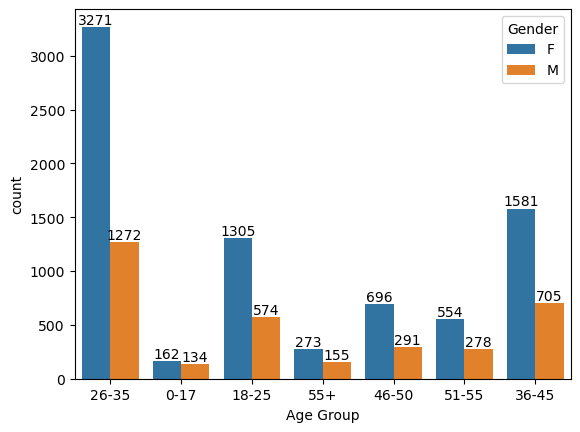

In [71]:
ax = sns.countplot(x='Age Group', hue = 'Gender',data = df)

for bars in ax.containers:
    ax.bar_label(bars)

Kelompok usia antara 26-35 tahun melakukan pembelian paling banyak, ditambah lagi mereka menghabiskan jumlah paling banyak dibandingkan kelompok usia lainnya. Dan terutama wanita berusia antara 26-35 tahun yang paling banyak membeli.

In [72]:
#jumlah total VS kelompok umur
df.groupby(['Age Group'])['Amount'].sum()

Age Group
0-17      2699653
18-25    17240732
26-35    42632348
36-45    22173353
46-50     9245656
51-55     8280383
55+       4090440
Name: Amount, dtype: int64

<Axes: xlabel='Age Group', ylabel='Amount'>

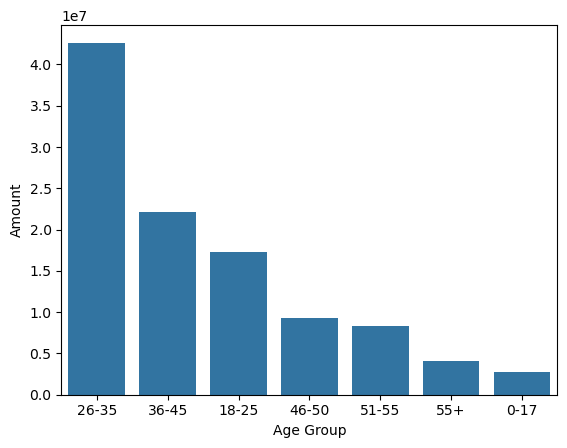

In [73]:
sales_age=df.groupby(['Age Group'],as_index= False)['Amount'].sum().sort_values(by='Amount',ascending = False)

sns.barplot(x='Age Group',y='Amount', data = sales_age)

(0.0, 25140.2)

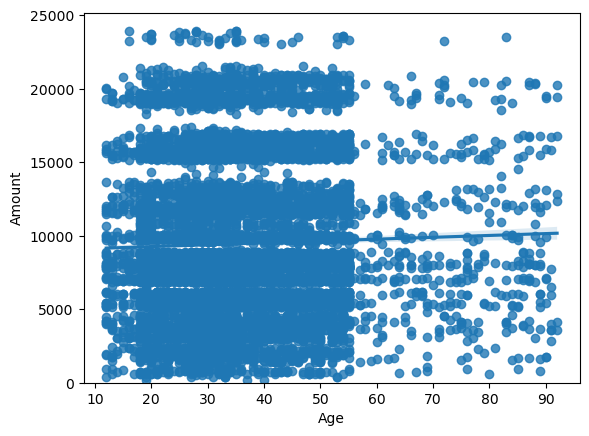

In [75]:
sns.regplot(x='Age',y='Amount',data = df)

plt.ylim(0,)

Pengelompokan Harga

In [76]:
bins = np.linspace(min(df['Amount']),max(df['Amount']),4)
group_name = ['Low','Medium','High']
df['Amount_binned'] = pd.cut(df['Amount'],bins,labels=group_name,include_lowest=True)
df['Amount_binned'].value_counts()

Amount_binned
Low       5623
Medium    4037
High      1591
Name: count, dtype: int64

Text(0.5, 1.0, 'Amount bins')

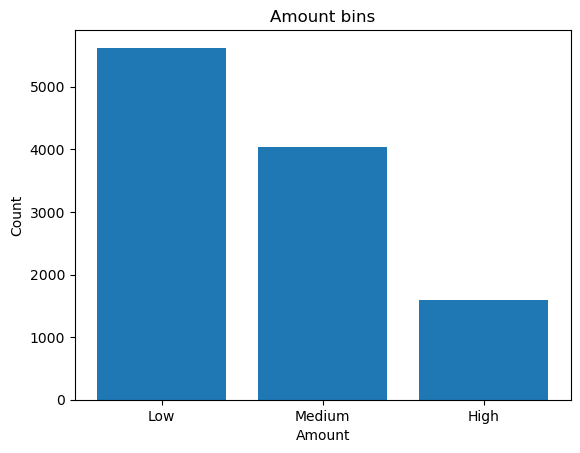

In [78]:
plt.bar(group_name,df['Amount_binned'].value_counts())

plt.xlabel('Amount')
plt.ylabel('Count')
plt.title('Amount bins')

In [79]:
#jumlah total pesanan dari 10 negara teratas
df.groupby(['State'],as_index=False)['Orders'].sum().sort_values(by='Orders', ascending = False).head(10)

,State,Orders
14,Uttar Pradesh,4813
10,Maharashtra,3811
7,Karnataka,3241
2,Delhi,2744
9,Madhya Pradesh,2259
0,Andhra Pradesh,2054
5,Himachal Pradesh,1568
8,Kerala,1137
4,Haryana,1109
3,Gujarat,1070


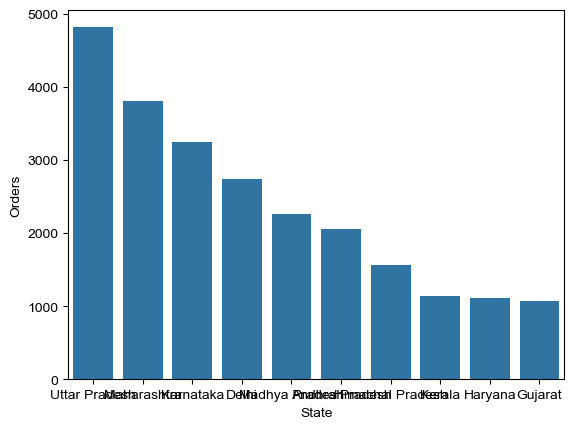

In [80]:
sales_state = df.groupby(['State'],as_index=False)['Orders'].sum().sort_values(by='Orders',ascending = False).head(10)

sns.barplot(x='State',y='Orders', data = sales_state)
sns.set(rc={'figure.figsize':(15,5)})

<Axes: xlabel='State', ylabel='Amount'>

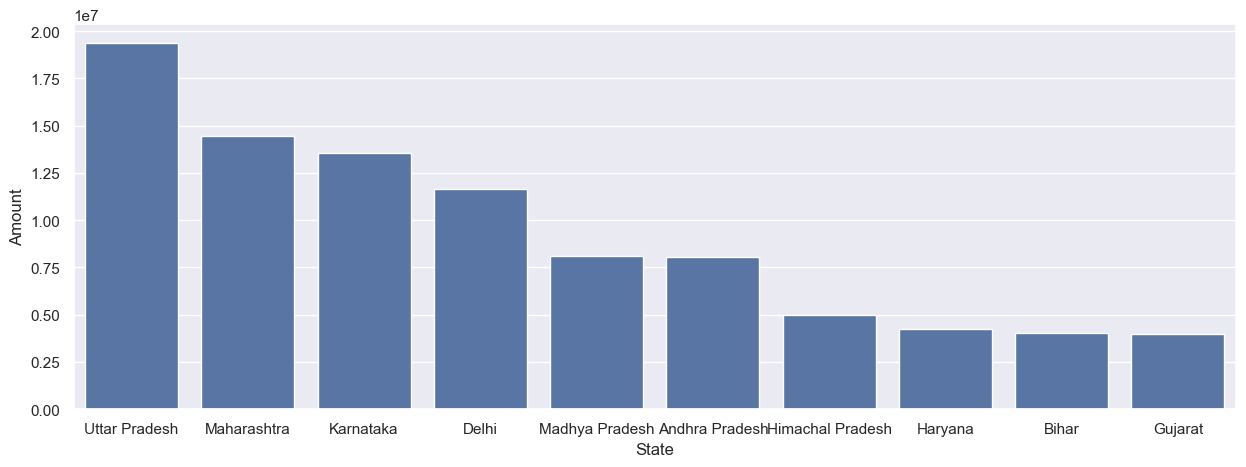

In [81]:
#jumlah total/penjualan dari 10 negara bagian teratas
sales_state = df.groupby(['State'],as_index = False)['Amount'].sum().sort_values(by='Amount',ascending = False).head(10)

sns.set(rc={'figure.figsize':(15,5)})
sns.barplot(data = sales_state, x= 'State', y='Amount')

Dari grafik di atas kita dapat melihat bahwa sebagian besar pesanan dan penjualan masing-masing berasal dari Uttar Pradesh, Maharashtra dan Karnataka.

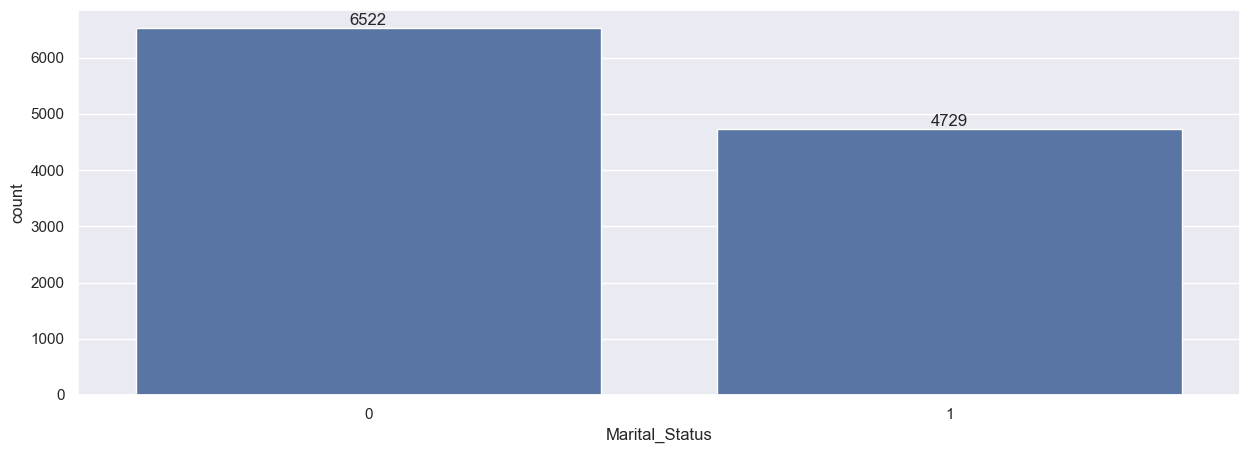

In [82]:
ax= sns.countplot(data = df, x='Marital_Status')

sns.set(rc={'figure.figsize':(8,6)})
for bars in ax.containers:
    ax.bar_label(bars)

In [83]:
df.groupby(['Marital_Status','Gender'],as_index = False)['Amount'].sum()

,Marital_Status,Gender,Amount
0,0,F,43815005
1,0,M,18348191
2,1,F,30615378
3,1,M,13583991


Perempuan apakah mereka sudah menikah atau belum, mereka telah membeli paling banyak. Dibandingkan dengan laki-laki/perempuan yang sudah menikah dan belum menikah, keduanya mempunyai pengeluaran paling besar.Jadi mereka yang belum menikah kemungkinan besar akan menghabiskan lebih banyak uang selama Musim Festival Diwali

<Axes: xlabel='Marital_Status', ylabel='Amount'>

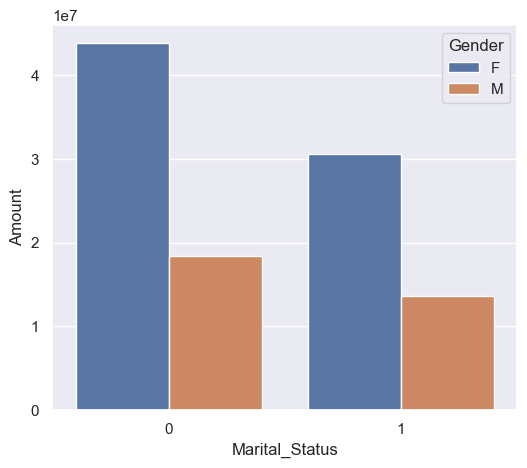

In [84]:
sales_marital_status = df.groupby(['Marital_Status','Gender'],as_index = False)['Amount'].sum()

sns.set(rc={'figure.figsize':(6,5)})
sns.barplot(x='Marital_Status',y='Amount', hue='Gender',data = sales_marital_status)

<Axes: xlabel='Marital_Status', ylabel='Amount'>

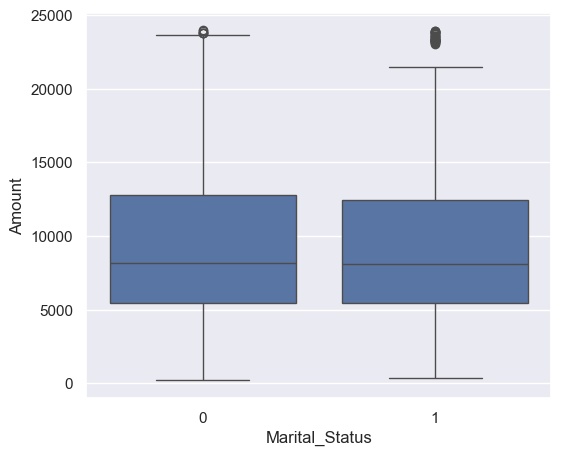

In [86]:
sns.boxplot(x='Marital_Status',y='Amount',data=df)

In [88]:
group_name = df[['State','Gender','Amount']]
group_name.head()

,State,Gender,Amount
0,Maharashtra,F,23952
1,Andhra Pradesh,F,23934
2,Uttar Pradesh,F,23924
3,Karnataka,M,23912
4,Gujarat,M,23877


In [89]:
group_test1 = group_name.groupby(['State','Gender'], as_index=False).mean()
group_test1.sort_values(by='Amount',ascending=False)

,State,Gender,Amount
4,Delhi,F,11042.419441
14,Karnataka,F,10867.124590
29,Uttar Pradesh,M,9970.092496
28,Uttar Pradesh,F,9964.319738
0,Andhra Pradesh,F,9947.156757
8,Haryana,F,9840.910769
1,Andhra Pradesh,M,9828.509728
11,Himachal Pradesh,M,9730.102703
20,Maharashtra,F,9514.337534
5,Delhi,M,9380.112360


In [90]:
group_ptable = group_test1.pivot(index='State',columns='Gender')
group_ptable

Amount             
Gender                       F            M
State                                      
Andhra Pradesh     9947.156757  9828.509728
Bihar              9304.557756  9186.839695
Delhi             11042.419441  9380.112360
Gujarat            9256.400651  9207.155738
Haryana            9840.910769  8046.291339
Himachal Pradesh   7478.248227  9730.102703
Jharkhand          7402.556818  9242.939655
Karnataka         10867.124590  9204.035897
Kerala             8288.673981  9331.373134
Madhya Pradesh     8579.158320  9241.937500
Maharashtra        9514.337534  9317.028916
Punjab             7091.544776  8720.196970
Rajasthan          8345.261745  8121.524390
Telangana          9260.710526  9136.244898
Uttar Pradesh      9964.319738  9970.092496
Uttarakhand        7307.422018  9097.313725

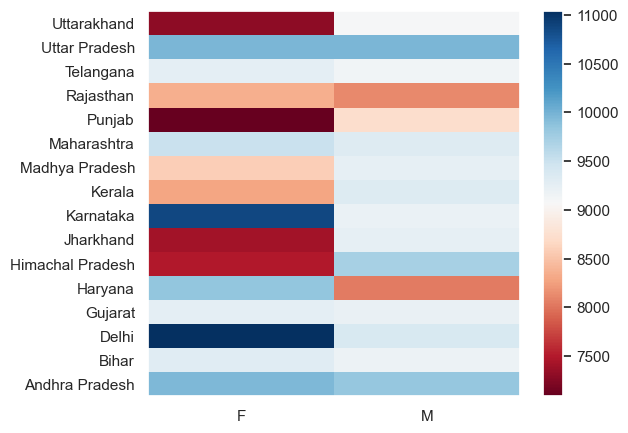

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline



fig,ax = plt.subplots()
im = ax.pcolor(group_ptable,cmap='RdBu')

row_labels = group_ptable.columns.levels[1]
col_labels = group_ptable.index

ax.set_xticks(np.arange(group_ptable.shape[1])+0.5,minor = False)
ax.set_yticks(np.arange(group_ptable.shape[0])+ 0.5, minor = False)

ax.set_xticklabels(row_labels,minor = False)
ax.set_yticklabels(col_labels,minor = False)

fig.colorbar(im)

Tujuan utama tabel pivot dan subplot adalah untuk melihat bagaimana pembelian didistribusikan antar negara bagian.Meskipun hal ini menunjukkan bahwa perempuan dari Delhi adalah pembeli utama.Ditambah lagi, saya baru saja mempelajarinya. Jadi saya mencobanya sekali lagi.

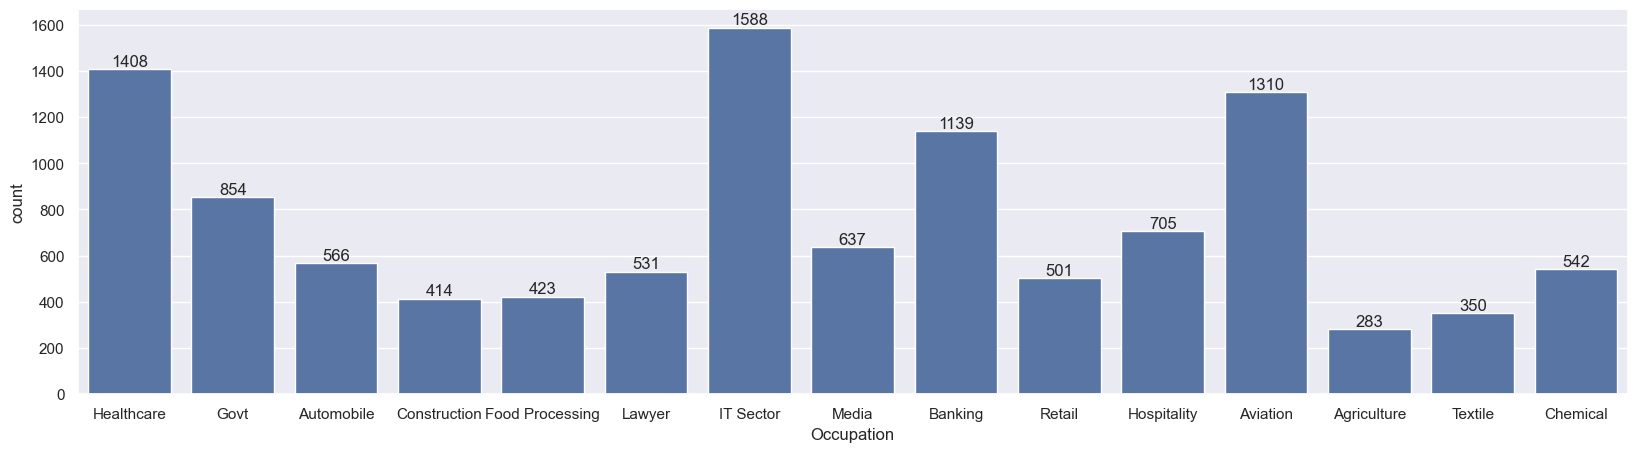

In [92]:
sns.set(rc={'figure.figsize':(20,5)})
ax=sns.countplot(x='Occupation',data=df)

for bars in ax.containers:
    ax.bar_label(bars)

In [93]:
df.groupby(['Occupation'],as_index = False)['Amount'].sum().sort_values(by='Amount',ascending = False)

,Occupation,Amount
10,IT Sector,14802344
8,Healthcare,13034586
2,Aviation,12602298
3,Banking,10789516
7,Govt,8517212
9,Hospitality,6395311
12,Media,6295832
1,Automobile,5378049
4,Chemical,5306889
11,Lawyer,4981665


<Axes: xlabel='Occupation', ylabel='Amount'>

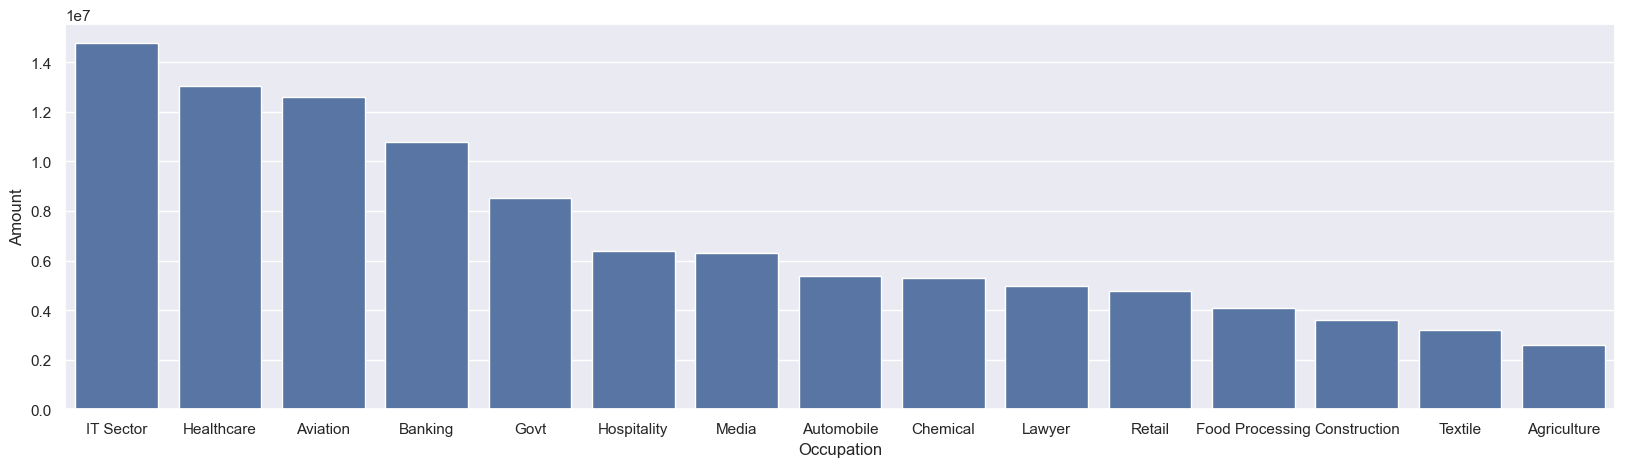

In [94]:
sales_occupation = df.groupby(['Occupation'],as_index = False)['Amount'].sum().sort_values(by='Amount',ascending = False)

sns.set(rc = {'figure.figsize':(20,5)})
sns.barplot(x='Occupation',y='Amount',data = sales_occupation)

Orang-orang yang bekerja di Sektor TI melakukan pembelian paling banyak, diikuti oleh Layanan Kesehatan, Penerbangan & Perbankan

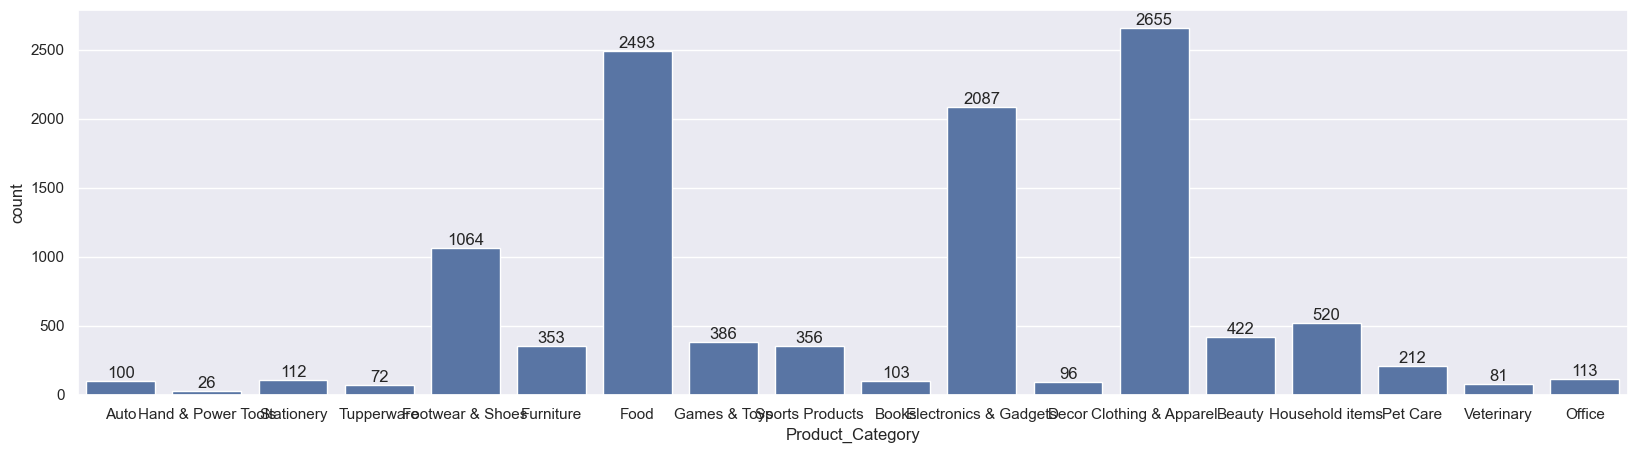

In [95]:
ax=sns.countplot(x='Product_Category',data=df)
sns.set(rc={'figure.figsize':(20,5)})

for bars in ax.containers:
    ax.bar_label(bars)

In [96]:
df.groupby(['Product_Category'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending = False)

,Product_Category,Amount
6,Food,33962242
3,Clothing & Apparel,16495019
5,Electronics & Gadgets,15643846
7,Footwear & Shoes,15622474
8,Furniture,5449504
9,Games & Toys,4331694
14,Sports Products,3635933
0,Auto,1986968
1,Beauty,1959484
15,Stationery,1676051


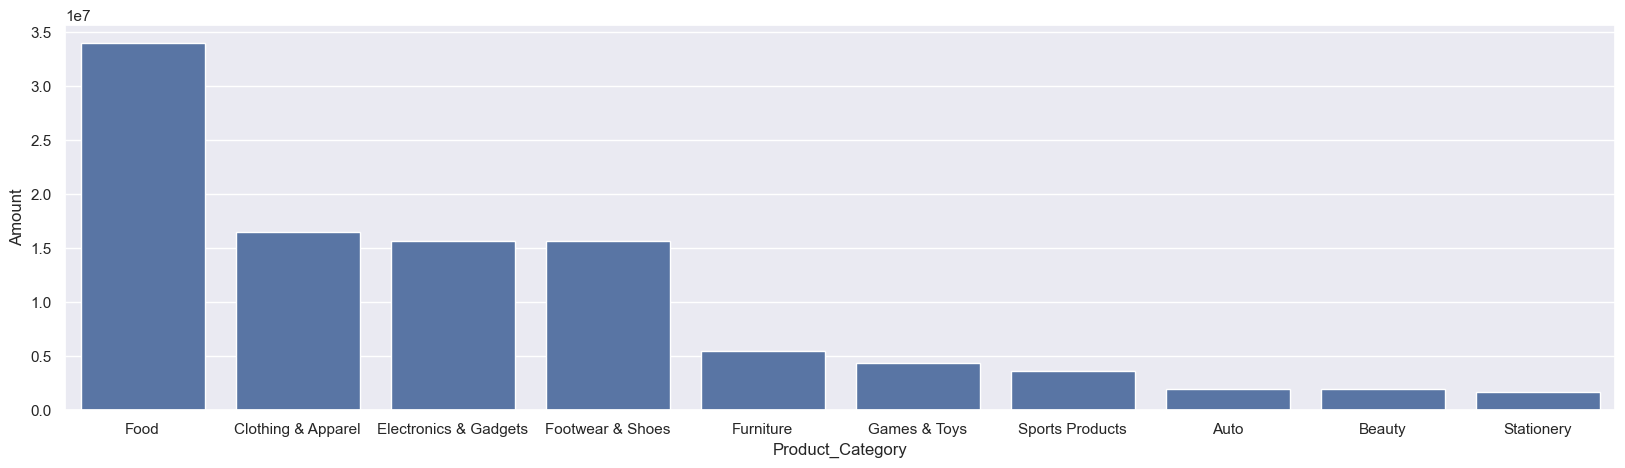

In [97]:
sales_product_category=df.groupby(['Product_Category'],as_index=False)['Amount'].sum().sort_values(by='Amount',ascending = False).head(10)

sns.barplot(x='Product_Category',y='Amount',data = sales_product_category)
sns.set(rc={'figure.figsize':(20,5)})

Seperti yang diharapkan, ini adalah musim festival, kebanyakan orang suka membeli makanan & pakaian. Orang-orang paling banyak memesan pakaian tetapi mereka menghabiskan lebih banyak uang untuk makanan, diikuti dengan pakaian

In [98]:
df.groupby(['Product_ID'],as_index= False)['Orders'].sum().sort_values(by='Orders',ascending = False)

,Product_ID,Orders
1680,P00265242,127
645,P00110942,116
1505,P00237542,91
1147,P00184942,82
680,P00114942,79
...,...,...
1079,P00177242,1
2122,P00337442,1
271,P00040042,1
1057,P00174342,1


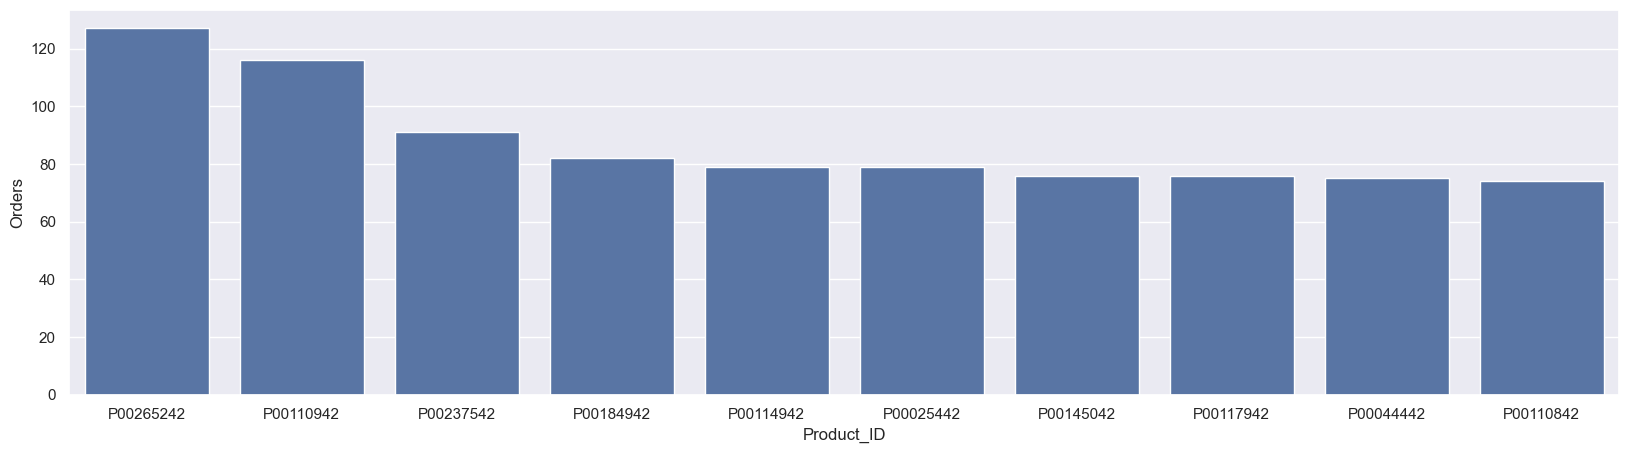

In [99]:
sales_product_id = df.groupby(['Product_ID'],as_index= False)['Orders'].sum().sort_values(by='Orders',ascending = False).head(10)

sns.barplot(x='Product_ID',y='Orders',data = sales_product_id)
sns.set(rc={'figure.figsize':(20,5)})

<Axes: xlabel='Product_ID'>

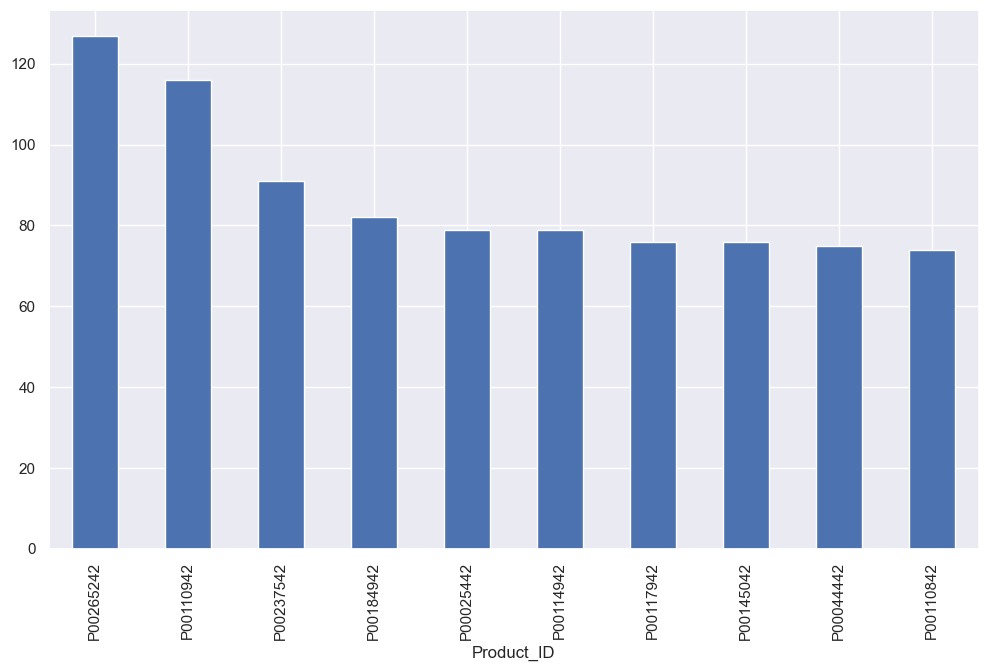

In [100]:
# 10 produk terlaris (sama seperti di atas)
fig1, ax1 = plt.subplots(figsize=(12,7))
df.groupby('Product_ID')['Orders'].sum().nlargest(10).sort_values(ascending=False).plot(kind='bar')

In [101]:
top_purchaser = df.groupby(['User_ID'],as_index= False)['Amount'].sum().sort_values(by='Amount',ascending = False)
print(top_purchaser.head(8))

      User_ID  Amount
1045  1001680  281034
1197  1001941  239147
2134  1003476  220435
1628  1002665  201104
2355  1003808  197660
2741  1004425  194343
2226  1003618  189921
274   1000424  187679


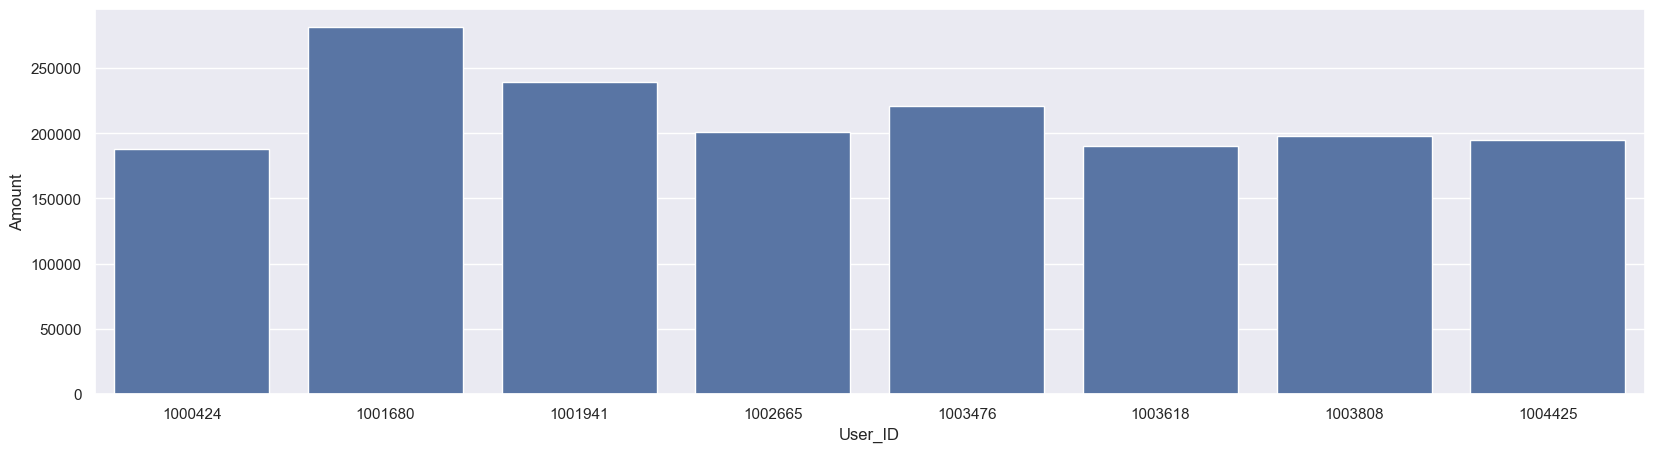

In [102]:
top_purchaser = df.groupby(['User_ID'],as_index= False)['Amount'].sum().sort_values(by='Amount',ascending = False).head(8)


sns.barplot(x='User_ID',y='Amount',data = top_purchaser)
sns.set(rc={'figure.figsize':(20,5)})

Ringkasan ProyekDalam proyek ini, saya mengeksplorasi bagaimana demografi dan kategori produk berinteraksi selama musim perayaan. Dengan menganalisis data menggunakan perpustakaan Pandas Python, saya menemukan wawasan seperti pria muda yang lebih menyukai barang elektronik dan pasangan menikah yang berfokus pada pembelian peralatan rumah tangga. Temuan ini dapat dimanfaatkan untuk menginformasikan pengambilan keputusan strategis untuk festival di masa depan.Misalnya, menyesuaikan kampanye pemasaran untuk menargetkan demografi tertentu dengan produk yang relevan dapat meningkatkan penjualan secara signifikan.Saya kemudian menggunakan Power BI untuk membuat dasbor interaktif yang memungkinkan pengguna menjelajahi data lebih jauh. Dasbor ini membantu mengidentifikasi produk unggulan (terlaris) untuk berbagai kelompok umur, pekerjaan, dan lokasi pelanggan. Pengguna dapat memanfaatkan filter dan pemotong untuk menelusuri detail spesifik.Secara keseluruhan, proyek ini menunjukkan kemampuan saya menggunakan Python untuk analisis data dan Power BI untuk membuat visualisasi interaktif yang ramah pengguna yang dapat menginformasikan keputusan bisnis berdasarkan data.